# 🧪 LAB: Machine Learning to Predict Concrete Compressive Strength

In this lab, you will apply `PyTorch` to a real-world data problem. You will implement a Neural Network in `PyTorch` using the new functionalities introduced this week and compare its performance with a Support Vector Machine and Linear Regression.

Your goal is to predict the **compressive strength of concrete** (the outcome variable, *Y*) based on a set of input features (*X*), including:
**Cement, Blast Furnace Slag, Fly Ash, Water, Superplasticizer, Coarse Aggregate, Fine Aggregate, and Age.**

This dataset and problem are based on the following paper:

- I-Cheng Yeh, "Modeling of strength of high performance concrete using artificial neural networks," Cement and Concrete Research, Vol. 28, No. 12, pp. 1797-1808 (1998). [Link to the paper](yeh1998.pdf).


---

**Collaboration Note**: This assignment is designed to support collaborative work. We encourage you to divide tasks among group members so that everyone can contribute meaningfully. Many components of the assignment can be approached in parallel or split logically across team members. Good coordination and thoughtful integration of your work will lead to a stronger final result.

---

In total, this lab assignment will be worth **100 points**.

--- 
**Submission notes**:

* Write down all group members' names, or at least the group name (if you have one and you previously provided it), in the first cell of the notebook.

* Verify that the notebook runs as expected and that all required outputs are included.

NAME(s) = "Laine Goldmacher, Max Magrill, Ashley Qin"

## 0. Overall Instructions 

In this lab, you will work with three models: a **Neural Network**, a **Support Vector Machine (SVM)**, and some form of **Linear Regression**. Each should meet the following requirements:

- **Do not tune the models**. For example, for the Neural Network, choose any number of layers and hidden units you prefer; for the SVM, select a kernel of your choice (e.g., linear, RBF, polynomial), etc.

- **Evaluate model performance using k-fold cross-validation**. That is, run each model using a chosen number of folds (*k*), and report the average performance across all folds. You may select the value of *k* that you want.

- **Be careful with data preprocessing**. Apply all preprocessing steps properly to avoid data leakage (e.g. standardizing features before data splitting)

## 1. Pre-implementation Group Discussion (15 points)

In your group, discuss, agree on, and elaborate the following points:

- **Descriptive analysis**. Identify what exploratory or descriptive analyses you can perform to better understand the relationship between each input variable and the outcome. Consider both visual (e.g., scatter plots, histograms) and statistical summaries.

- **Data preprocessing**. Decide what preprocessing steps are necessary given that you will be using neural networks. 

- **Model configuration**. Specify which cost function and output layer activation are most appropriate for your problem type (e.g., regression vs. classification). Explain your reasoning based on the nature of the outcome variable.

- **Performance evaluation**. Describe how you will perform k-fold cross-validation to assess your model’s performance. Include how you will divide the data, compute metrics across folds, and report the final averaged results.

Descriptive analysis: 
- Visually, we will create scatter plots and histograms to compare every input variable to y. This will allow us to visualize the spread of the data and how heavily the variables are correlated.
- Statistically, we will look at correlation matrices, as well as the mean, median, and standard deviation for each input variable. Since each input variable is numerical, these summaries will help us to analyze the distributions and relationships in the data.

Data Preprocessing:
- We will use 5-fold cross-validation to evaluate our models, dividing the dataset into five equally sized folds. For each iteration, four folds will be used for training and one for validation. We will standardize the input features because they have different numerical scales, which can disproportionately influence neural network training and gradient updates. To prevent data leakage, we will fit the StandardScaler only on the training observations within each fold and use that fitted scaler to transform both the training and validation data.

Model configuration:
- Our problem type is looking to predict a numeric value, so regression is the most appropriate model here. Therefore, we will use MSE as our cost function and the identity function as our output layer activation function, as we did in the last lab. We will use ReLU as the hidden layer activation function with 1 layer and 5 hidden units, as instructed. We will use a learning rate of 0.01 because it worked well in the previous lab.
- As for SVM, we will use Radial Basis Function (RBF) kernel for regression. Since concrete compressive strength is influenced by many factors, we expect the relationships between the 8 input features and target variable to be nonlinear. The RBF kernel can capture these complex relationships and interactions, and training an RBF SVM is computationally feasible. For SVR, we will use the standard epsilon-insensitive loss function, which penalizes predictions that fall outside a specified margin of error. We will use MSE to evaluate the model's performance and compare it with the neural network and linear regression models. We will set the C and epsilon hyperparameters to 1.0 and 0.1 respectively as these are the default settings.
  
Performance evaluation:
- We will use 5-fold cross validation because our dataset has 1030 entries, which will have each model training on ~80% of our observations. 5-fold cross validation shuffles the data and divides it into 5 equal folds (206 observations). Each iteration will train the model on 4 folds (824 observations, or 80% of the data). We will evaluate the performance on the remaining, fifth fold. This process will be repeated 5 times so that each fold serves as the holdout set exactly once. For each iteration, we will calculate Mean Squared Error (MSE) to assess prediction accuracy. Finally, we will average the MSE across all five folds and report the mean and standard deviation to summarize the model's overall performance and consistency.

In [9]:
# data loading
import pandas as pd
data = pd.read_excel('Concrete_Data.xls')
data.head()


,Cement (component 1)(kg in a m^3 mixture),Blast Furnace Slag (component 2)(kg in a m^3 mixture),Fly Ash (component 3)(kg in a m^3 mixture),Water (component 4)(kg in a m^3 mixture),Superplasticizer (component 5)(kg in a m^3 mixture),Coarse Aggregate (component 6)(kg in a m^3 mixture),Fine Aggregate (component 7)(kg in a m^3 mixture),Age (day),"Concrete compressive strength(MPa, megapascals)"
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.986111
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.887366
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.269535
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.052780
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.296075


In [10]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 1030 entries, 0 to 1029
Data columns (total 9 columns):
 #   Column                                                 Non-Null Count  Dtype  
---  ------                                                 --------------  -----  
 0   Cement (component 1)(kg in a m^3 mixture)              1030 non-null   float64
 1   Blast Furnace Slag (component 2)(kg in a m^3 mixture)  1030 non-null   float64
 2   Fly Ash (component 3)(kg in a m^3 mixture)             1030 non-null   float64
 3   Water  (component 4)(kg in a m^3 mixture)              1030 non-null   float64
 4   Superplasticizer (component 5)(kg in a m^3 mixture)    1030 non-null   float64
 5   Coarse Aggregate  (component 6)(kg in a m^3 mixture)   1030 non-null   float64
 6   Fine Aggregate (component 7)(kg in a m^3 mixture)      1030 non-null   float64
 7   Age (day)                                              1030 non-null   int64  
 8   Concrete compressive strength(MPa, megapascals)        1030 

## 2. Descriptive analysis (10 points)

Apply the descriptive analyses that your group agreed upon in the previous section.

**Load the dataset before beginning the descriptive analysis; you will also use it in the following sections.**

In [11]:
import numpy as np
import matplotlib.pyplot as plt

# shorten the long column names so plots and tables are readable
data.columns = ['Cement', 'Slag', 'FlyAsh', 'Water', 'Superplasticizer',
                'CoarseAgg', 'FineAgg', 'Age', 'Strength']
features = data.columns[:-1]
target = 'Strength'

print(data.shape)
print("Missing values per column:\n", data.isna().sum())

(1030, 9)
Missing values per column:
 Cement              0
Slag                0
FlyAsh              0
Water               0
Superplasticizer    0
CoarseAgg           0
FineAgg             0
Age                 0
Strength            0
dtype: int64


### 2.1 Statistical summaries
Mean, median, and standard deviation of each variable (plus min/max to see the range).

In [12]:
summary = pd.DataFrame({
    'mean': data.mean(),
    'median': data.median(),
    'std': data.std(),
    'min': data.min(),
    'max': data.max(),
    'pct_zero': (data == 0).mean() * 100,
}).round(2)
summary

,mean,median,std,min,max,pct_zero
Cement,281.17,272.90,104.51,102.00,540.0,0.00
Slag,73.90,22.00,86.28,0.00,359.4,45.24
FlyAsh,54.19,0.00,64.00,0.00,200.1,54.95
Water,181.57,185.00,21.36,121.75,247.0,0.00
Superplasticizer,6.20,6.35,5.97,0.00,32.2,36.80
CoarseAgg,972.92,968.00,77.75,801.00,1145.0,0.00
FineAgg,773.58,779.51,80.18,594.00,992.6,0.00
Age,45.66,28.00,63.17,1.00,365.0,0.00
Strength,35.82,34.44,16.71,2.33,82.6,0.00


### 2.2 Histograms
Distribution of each input variable and of the outcome.

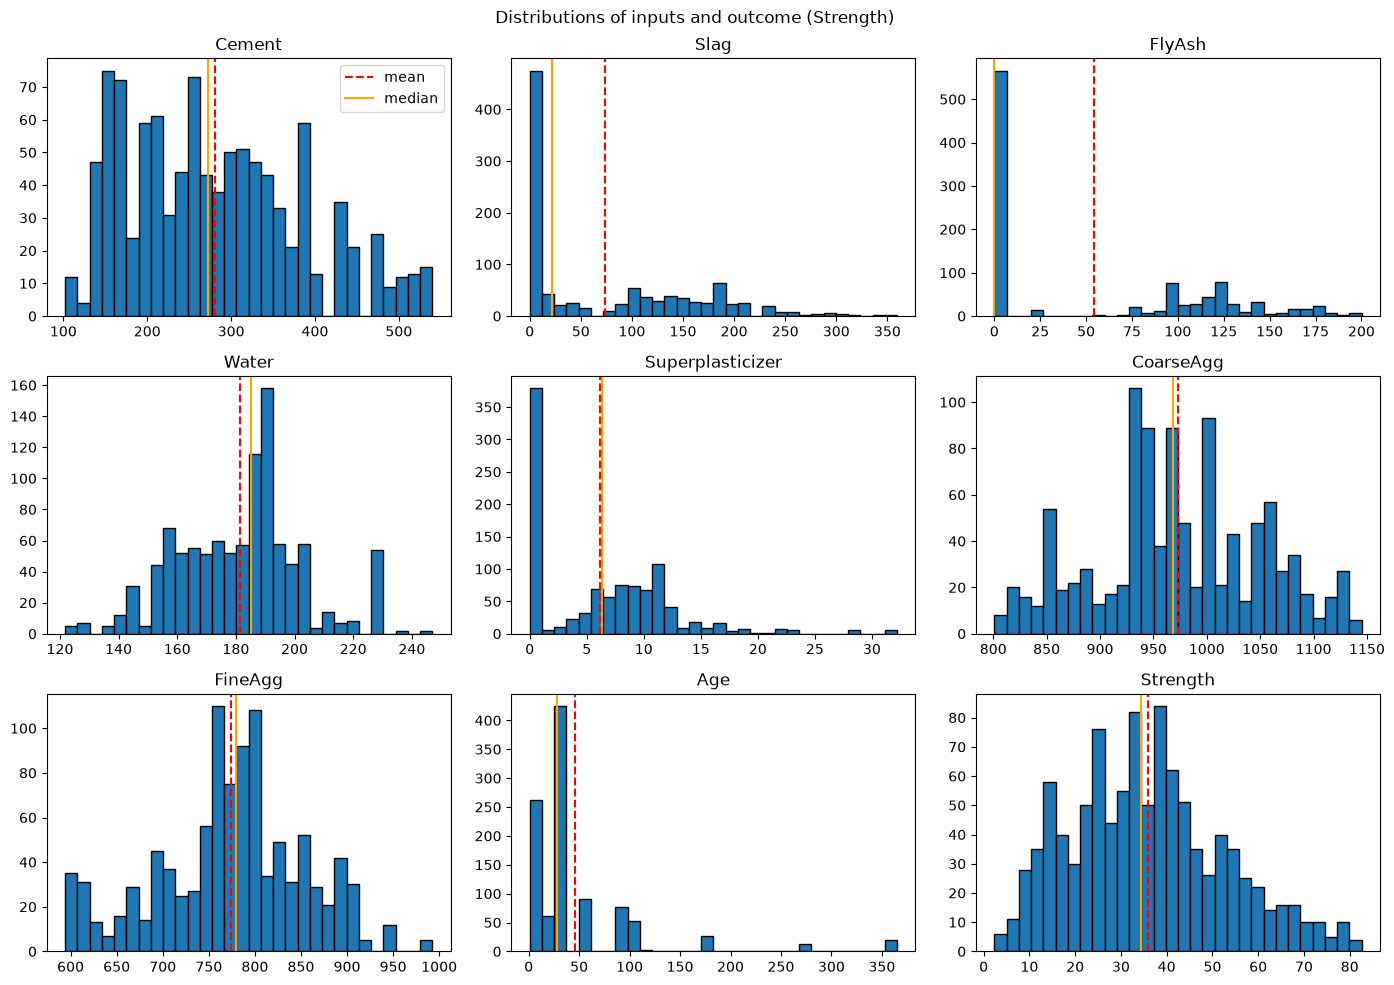

In [13]:
fig, axes = plt.subplots(3, 3, figsize=(14, 10))
for ax, col in zip(axes.flat, data.columns):
    ax.hist(data[col], bins=30, edgecolor='black')
    ax.axvline(data[col].mean(), color='red', linestyle='--', label='mean')
    ax.axvline(data[col].median(), color='orange', linestyle='-', label='median')
    ax.set_title(col)
axes.flat[0].legend()
plt.suptitle('Distributions of inputs and outcome (Strength)')
plt.tight_layout()
plt.show()

### 2.3 Scatter plots: each input vs. Strength
Each panel shows one input against the outcome, with a fitted least-squares line and the Pearson correlation *r* in the title.

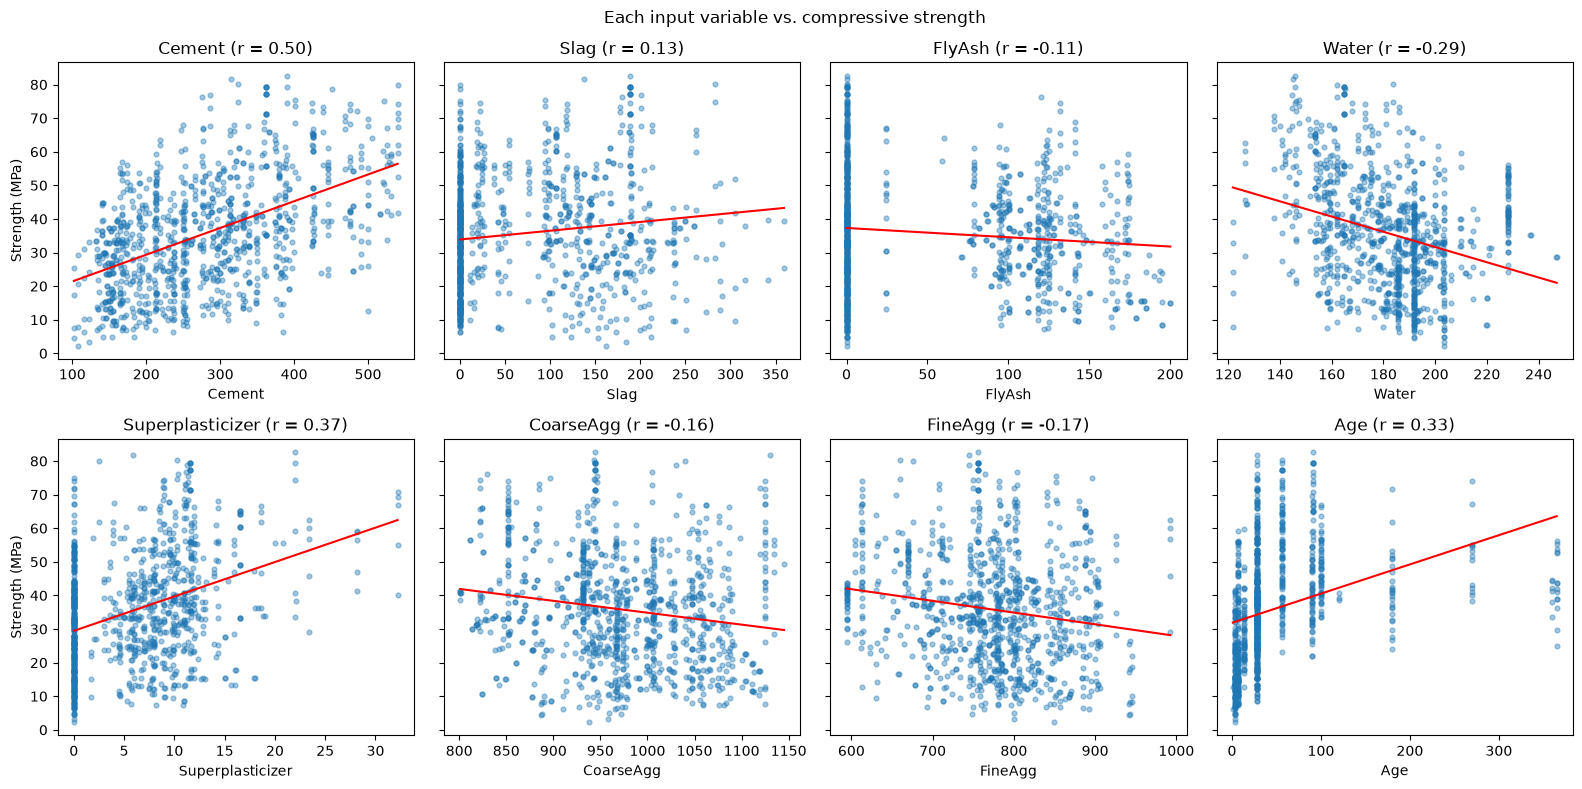

In [14]:
fig, axes = plt.subplots(2, 4, figsize=(16, 8), sharey=True)
for ax, col in zip(axes.flat, features):
    x, y = data[col], data[target]
    ax.scatter(x, y, alpha=0.4, s=12)
    slope, intercept = np.polyfit(x, y, 1)
    xs = np.linspace(x.min(), x.max(), 100)
    ax.plot(xs, slope * xs + intercept, color='red')
    ax.set_title(f'{col} (r = {x.corr(y):.2f})')
    ax.set_xlabel(col)
for ax in axes[:, 0]:
    ax.set_ylabel('Strength (MPa)')
plt.suptitle('Each input variable vs. compressive strength')
plt.tight_layout()
plt.show()

### 2.4 Correlation matrix
Pearson correlations between all variables, including each input's correlation with `Strength`.

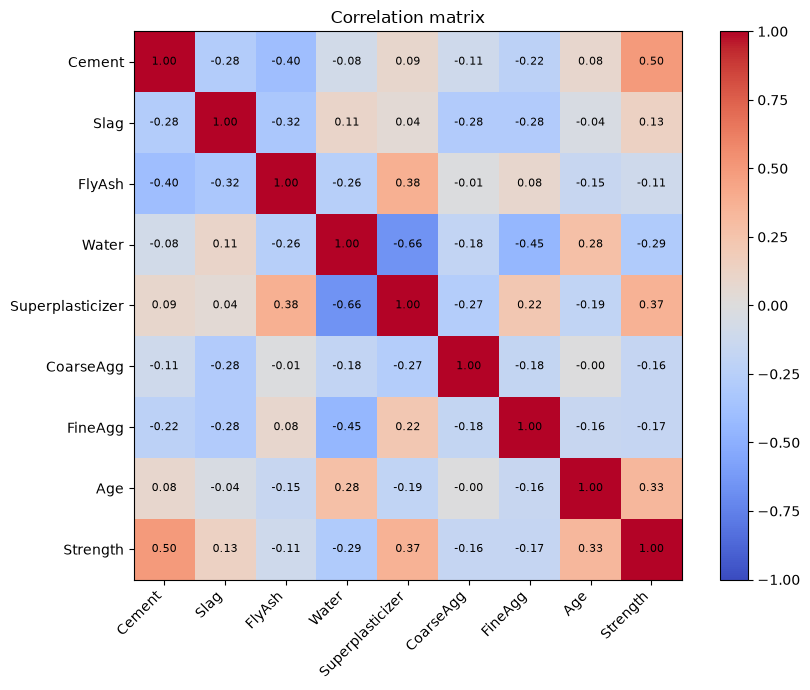

Cement              0.498
Superplasticizer    0.366
Age                 0.329
Water              -0.290
FineAgg            -0.167
CoarseAgg          -0.165
Slag                0.135
FlyAsh             -0.106
Name: Strength, dtype: float64

In [15]:
corr = data.corr()

fig, ax = plt.subplots(figsize=(9, 7))
im = ax.imshow(corr, cmap='coolwarm', vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)))
ax.set_xticklabels(corr.columns, rotation=45, ha='right')
ax.set_yticks(range(len(corr)))
ax.set_yticklabels(corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f'{corr.iloc[i, j]:.2f}', ha='center', va='center', fontsize=8)
fig.colorbar(im, ax=ax)
ax.set_title('Correlation matrix')
plt.tight_layout()
plt.show()

# correlation of each input with the outcome, strongest first
corr[target].drop(target).sort_values(key=abs, ascending=False).round(3)

### 2.5 Key findings
- **Data quality:** 1030 observations, 8 numeric inputs, 1 numeric outcome, and no missing values. No imputation is needed.
- **Very different scales:** the inputs range from about 0–32 (Superplasticizer) up to 800–1145 (CoarseAgg), and their standard deviations differ by more than 10×. This supports our plan to standardize the features (fitted on training folds only) before training the neural network.
- **Skewed and zero-inflated inputs:** Slag (45% zeros), FlyAsh (55% zeros), and Superplasticizer (37% zeros) have large spikes at 0, because many mixtures leave those components out entirely. For these variables the mean is well above the median. Age is strongly right-skewed (median 28 days, max 365) and takes only a few discrete values (1, 3, 7, 14, 28, 56, 90, …).
- **Outcome:** Strength is roughly bell-shaped and slightly right-skewed (mean 35.8 vs. median 34.4 MPa, range 2.3–82.6). It is continuous, so this is a **regression** problem.
- **Relationships with Strength:** Cement has the strongest correlation (r = 0.50), followed by Superplasticizer (0.37) and Age (0.33). Water is negatively correlated (−0.29). Slag, FlyAsh, CoarseAgg, and FineAgg are only weakly correlated (|r| < 0.17).
- **Nonlinearity:** the scatter plots have a lot of spread around the linear fits, and no single input explains much of the variance. Age in particular looks nonlinear: strength rises quickly over the first ~28–56 days and then levels off. This suggests a nonlinear model such as a neural network or an RBF SVM should do better than plain linear regression.
- **Correlation among inputs:** Water and Superplasticizer are fairly strongly negatively correlated (r = −0.66), and Water and FineAgg are moderately negatively correlated (−0.45). The negative correlation between water and superplasticizer is consistent with the use of superplasticizers to reduce the amount of water needed in concrete mixtures. Some coefficients in a linear model may therefore be hard to interpret, but the correlation is not extreme.

## 3. Neural Network (40 points)

Implement a neural network as you did in the previous lab, but this time leverage the new functionalities introduced this week. Specifically:

- Your class implementing the neural network should inherit from nn.Module.

- Use `nn.Linear` for the linear transformations between layers, `nn.ReLU` for the hidden-layer activations, and the appropriate activation function for the output layer (e.g., `nn.Sigmoid` for binary classification).

- Use the appropriate cost function from `torch.nn` for your task (e.g., `nn.MSELoss`, `nn.BCELoss`).

- Use Adam from `torch.optim` as the optimizer.

- Use `DataLoader` to efficiently do batch processing. You may choose the batch size freely.

Once you have implemented this class, create an instance of it, then train and evaluate your model on the lab dataset.

**Remember to follow the general requirements regarding model tuning, evaluation, and data preprocessing described earlier.**

In [16]:
# preprocessing
import numpy as np
import torch
import torch.nn as nn

from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import KFold
from sklearn.preprocessing import StandardScaler

torch.manual_seed(42)
np.random.seed(42)

X = data[['Cement', 'Slag', 'FlyAsh', 'Water', 'Superplasticizer', 'CoarseAgg', 'FineAgg', 'Age']].values
y = data['Strength'].values

kf = KFold(n_splits=5, shuffle=True, random_state=42)

In [17]:
class ConcreteNN(nn.Module):

    def __init__(self):
        super().__init__()
        l1 = nn.Linear(8, 5)
        a1 = nn.ReLU()
        l2 = nn.Linear(5, 1)
        l = [l1, a1, l2]
        self.module_list = nn.ModuleList(l)

    def forward(self, X):
        for f in self.module_list:
            X = f(X)
        return X

In [18]:
mse_scores = []

batch_size = 16
epochs = 100
learning_rate = 0.01

for fold, (train_idx, val_idx) in enumerate(kf.split(X), 1):

    X_train, X_val = X[train_idx], X[val_idx]
    y_train, y_val = y[train_idx], y[val_idx]

    scaler = StandardScaler()
    X_train = scaler.fit_transform(X_train)
    X_val = scaler.transform(X_val)

    X_train = torch.tensor(X_train, dtype=torch.float32)
    X_val = torch.tensor(X_val, dtype=torch.float32)
    y_train = torch.tensor(y_train, dtype=torch.float32).reshape(-1, 1)
    y_val = torch.tensor(y_val, dtype=torch.float32).reshape(-1, 1)

    train_dataset = TensorDataset(X_train, y_train)
    train_loader = DataLoader(
        train_dataset,
        batch_size=batch_size,
        shuffle=True
    )

    model = ConcreteNN()

    criterion = nn.MSELoss()
    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=learning_rate
    )

    for epoch in range(epochs):

        model.train()

        for X_batch, y_batch in train_loader:

            optimizer.zero_grad()
            predictions = model(X_batch)
            loss = criterion(predictions, y_batch)
            loss.backward()
            optimizer.step()

    model.eval()

    with torch.no_grad():
        y_pred = model(X_val)
        mse = criterion(y_pred, y_val).item()

    mse_scores.append(mse)

    print(f"Fold {fold}: MSE = {mse:.4f}")

print("\nAverage Cross-Validation Results:")
print(f"Mean MSE: {np.mean(mse_scores):.4f}")
print(f"Standard Deviation: {np.std(mse_scores):.4f}")

Fold 1: MSE = 97.0009
Fold 2: MSE = 131.1038
Fold 3: MSE = 120.1424
Fold 4: MSE = 92.7759
Fold 5: MSE = 100.8260

Average Cross-Validation Results:
Mean MSE: 108.3698
Standard Deviation: 14.7293


## 4. Replication (10 points)

Replicate your neural network experiment using the corresponding model class from `scikit-learn`: https://scikit-learn.org/stable/api/sklearn.neural_network.html. Be sure to apply the same neural network architecture as well as the same procedures for model evaluation and preprocessing to ensure a fair comparison.

**Remember**: Follow the general requirements regarding model tuning, evaluation, and data preprocessing described earlier.

In [19]:
from sklearn.neural_network import MLPRegressor
from sklearn.model_selection import KFold
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error
import numpy as np

kf = KFold(n_splits=5, shuffle=True, random_state=42)

mse_scores_sklearn = []

for fold, (train_idx, val_idx) in enumerate(kf.split(X), 1):

    X_train, X_val = X[train_idx], X[val_idx]
    y_train, y_val = y[train_idx], y[val_idx]

    scaler = StandardScaler()
    X_train = scaler.fit_transform(X_train)
    X_val = scaler.transform(X_val)

    model = MLPRegressor(
    hidden_layer_sizes=(5,),
    activation='relu',
    solver='adam',
    learning_rate_init=0.01,
    batch_size=16,
    max_iter=100,
    shuffle=True,
    random_state=42,
    alpha=0.0,
    tol=0.0,
    n_iter_no_change=101)

    model.fit(X_train, y_train)

    y_pred = model.predict(X_val)
    mse = mean_squared_error(y_val, y_pred)
    mse_scores_sklearn.append(mse)

    print(f"Fold {fold}: MSE = {mse:.4f}")

print("\nAverage Cross-Validation Results (sklearn):")
print(f"Mean MSE: {np.mean(mse_scores_sklearn):.4f}")
print(f"Standard Deviation: {np.std(mse_scores_sklearn):.4f}")

/Users/maxmagrill/Desktop/UVA/DS/DS 4022 - Machine Learning 2/ML-Labs/.venv/lib/python3.14/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (100) reached and the optimization hasn't converged yet.
  warnings.warn(
/Users/maxmagrill/Desktop/UVA/DS/DS 4022 - Machine Learning 2/ML-Labs/.venv/lib/python3.14/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (100) reached and the optimization hasn't converged yet.
  warnings.warn(


Fold 1: MSE = 44.0886
Fold 2: MSE = 57.0333


/Users/maxmagrill/Desktop/UVA/DS/DS 4022 - Machine Learning 2/ML-Labs/.venv/lib/python3.14/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (100) reached and the optimization hasn't converged yet.
  warnings.warn(
/Users/maxmagrill/Desktop/UVA/DS/DS 4022 - Machine Learning 2/ML-Labs/.venv/lib/python3.14/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (100) reached and the optimization hasn't converged yet.
  warnings.warn(


Fold 3: MSE = 50.1102
Fold 4: MSE = 54.0086
Fold 5: MSE = 39.9461

Average Cross-Validation Results (sklearn):
Mean MSE: 49.0374
Standard Deviation: 6.2760


/Users/maxmagrill/Desktop/UVA/DS/DS 4022 - Machine Learning 2/ML-Labs/.venv/lib/python3.14/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (100) reached and the optimization hasn't converged yet.
  warnings.warn(


## 5. Comparison (20 points)

Apply a Support Vector Machine (SVM) and Linear Regression model to the dataset, and compare their performance with that of your Neural Network.

Discuss any similarities or differences you observe in their results and provide possible explanations for these patterns.

Be sure to apply the k-fold cross-validation procedure to ensure a fair comparison across all models.

**Remember**: Follow the general requirements regarding model tuning, evaluation, and data preprocessing described earlier.

In [22]:
# USE AS MANY CELLS AS NEEDED
from sklearn.svm import SVR
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.model_selection import cross_val_score, KFold

model = {
    "SVR (RBF)" : make_pipeline(StandardScaler(), SVR(kernel='rbf')),
    "Linear Regression" : make_pipeline(StandardScaler(), LinearRegression())
}

results = {"NN (Pytorch)" : mse_scores, "NN (sklearn)" : mse_scores_sklearn}
for name, m in model.items():
    results[name] = -cross_val_score(m, X, y, cv=KFold(n_splits=5, shuffle=True, random_state=42), scoring='neg_mean_squared_error')

fold_var = np.array([np.var(y[val_idx]) for _, val_idx in kf.split(X)])

pd.DataFrame({k: {"Mean MSE": np.mean(v), "Std MSE": np.std(v),
                  "Mean R2": np.mean(1 - np.array(v) / fold_var)}
              for k, v in results.items()}).T.round(3)


,Mean MSE,Std MSE,Mean R2
NN (Pytorch),108.370,14.729,0.610
NN (sklearn),49.037,6.276,0.824
SVR (RBF),98.690,18.837,0.648
Linear Regression,111.011,17.154,0.601


**Discussion**

Using the same 5 folds and fitting the scaler only on the training data in each fold, the scikit-learn neural network performed best by a wide margin (MSE 49.0, R² = 0.82). The SVR had an MSE of 98.7 (R² = 0.65), the PyTorch neural network 108.4 (R² = 0.61), and linear regression 111.0 (R² = 0.60). Linear regression can only capture the linear effects of inputs such as Cement and Water, and it misses nonlinear patterns such as Age, where strength rises quickly and then levels off. The scikit-learn network's ReLU hidden layer can model these patterns, which explains why it cut the error by more than half. The SVR's RBF kernel adds some nonlinearity, but the default C=1 regularizes it heavily relative to the scale of the target, so it underfits and improves only slightly on linear regression. The PyTorch network had the same setup as the scikit-learn network but performed about as well as linear regression, suggesting it failed to learn the nonlinear patterns within 100 epochs. This likely comes from differences in initial weights between the two libraries and from the unstandardized target. Large early gradients may have pushed some ReLU units into always outputting zero, leaving a nearly linear model whose results mirror linear regression's.

## 6. Collaboration Reflection (5 points)

As a group, identify **one specific challenge or inefficiency** you encountered while working on this lab. In 3–5 sentences:

1. Briefly describe what happened and how it affected your work.
2. Identify one concrete action your group will take to avoid or better manage this issue in the next lab.

If your group encountered no major problem, identify one aspect of your collaboration that could still be improved.

YOUR TEXT HERE